In [27]:
import seaborn as sns
import pandas as pd
import csv
import numpy as np
from scipy.signal import welch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import random as rd
import os

In [28]:
df = pd.read_csv('CNMFe_004.csv')

cols = df.loc[0].eq(" accepted")
cols = cols.index[cols]
cols = list(cols)

df_data = df[[" ",*cols]].drop([0])
df_data = df_data.astype(np.double)
df_data.loc[6005:,' '] -= 216
df_data.loc[12010:,' '] -= 246
df_data = df_data.drop([287])
df_data.describe()

C:\Users\stefa\AppData\Local\Programs\Python\Python39\lib\site-packages\IPython\core\interactiveshell.py:3437: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,,C00,C07,C09,C14,C15,C16,C17,C19,C21,...,C58,C60,C75,C82,C83,C84,C87,C89,C90,C91
count,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,...,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000,30024.000000
mean,876.480500,3.205598,1.328075,4.289199,1.899549,2.189520,0.634738,0.580191,0.006373,12.483342,...,1.606913,1.046442,1.057897,4.134676,3.686988,2.575202,0.515072,20.746128,13.881046,17.270926
std,605.652811,5.780312,3.143838,8.341913,4.907091,3.921286,2.237455,1.894081,1.717642,10.042096,...,3.709868,2.076226,2.232842,8.030422,6.458437,5.476959,2.209329,23.989381,23.943388,42.040293
min,0.000000,-9.957884,-3.688468,-23.708440,-22.015930,-5.634704,-10.881670,-9.758370,-7.665618,-20.090360,...,-4.612504,-10.943020,-8.397240,-9.972333,-5.079432,-6.221764,-4.038476,2.011537,0.750723,1.044721
25%,382.679971,0.378081,-0.328442,2.113295,0.340378,0.360487,-0.435632,-0.459368,-0.858651,4.475276,...,-0.048818,-0.011535,-0.049152,0.034361,0.366566,0.363480,-0.466773,4.675016,2.640680,2.771830
50%,688.845903,1.319594,0.446831,3.138720,1.299727,1.168824,0.343708,0.381867,-0.075942,10.056225,...,0.820086,0.960296,0.950747,1.475846,1.355182,1.312950,0.248075,11.387715,5.349587,3.720853
75%,1326.645912,3.174742,1.501594,4.198184,2.355598,2.133094,1.189693,1.286052,0.701602,18.725908,...,1.839906,1.908002,1.942427,4.487056,3.577951,2.483429,1.005222,28.277613,12.768420,12.031298
max,1984.279883,55.815340,22.481320,142.069400,97.066440,27.623040,30.499960,27.841160,29.678460,55.607720,...,36.144790,40.296230,44.460920,83.739680,48.243500,52.490200,32.189000,158.091900,189.308200,423.765800


In [30]:
df_s = pd.read_csv("spikes_deconvolve_CNMFe_004.csv")
S_vals = df_s.transpose().to_numpy()
S_vals = S_vals[1:]

In [41]:
def get_rectangle(x,y,w,h,c):
    return mpatches.Rectangle((x,y),w,h, 
                        fill = True,
                        alpha=0.5,
                        color = c)

In [32]:
def plot_data(colored_sections=False,data_x_locations=[],data_x_colors=False,data_x_palette=False,black_traces=False,output_folder="output_deconvolve",split_figures=False):
    if not os.path.isdir(output_folder):
        os.makedirs(output_folder)
    palette = sns.color_palette('viridis',as_cmap=True).colors

    step = int(len(palette)/len(cols))

    if black_traces:
        palette = ['#000' for i in range(len(palette))]

    color_indices = [i*step for i in range(len(cols))]
    if data_x_colors:
        colors = data_x_colors
    else:
        colors = [0,0,1,0,0,1,4,1,2,0,1,0,0,0,1]
    
    rd.shuffle(color_indices)
    
    if not data_x_palette:
        palette_r = sns.color_palette("bright")
    else:
        palette_r = data_x_palette
    
    #Shuffle colors
#     color_indices = [0, 100, 25, 200, 50, 175, 75, 125, 150, 225]
    if split_figures:
        for i in range(len(cols)):
            fig, ax = plt.subplots(1, 1)
            fig = plt.gcf()
            fig.set_size_inches([20,1*1.322])
            sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax,color=palette[color_indices[i]])
            max_val = df_data[cols[i]].max()
            min_val = df_data[cols[i]].min()

            if(colored_sections):
                for j,pair in enumerate(data_x_locations):
                    ax.add_patch(get_rectangle(pair[0],min_val,pair[1],abs(min_val)+max_val,palette_r[colors[j]]))

            ax.plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
            ax.plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')
            ax.spines['right'].set_visible(False)
            ax.spines['top'].set_visible(False)
            ax.spines['left'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            ax.set_xlim([0,900])

            max_val = S_vals[i].max()
            min_val = S_vals[i].min()
            fig.tight_layout()
            fig.savefig(f"{output_folder}/CNMFE_{cols[i]}.jpg",dpi=500)
            
            fig, ax = plt.subplots(1, 1)
            fig = plt.gcf()
            fig.set_size_inches([20,1*1.322])
            
            sns.lineplot(data=df_data,x=" ",y=S_vals[i],ax=ax,color=palette[color_indices[i]])
            ax.plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
            ax.plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')
            if(colored_sections):
                for j,pair in enumerate(data_x_locations):
                    ax.add_patch(get_rectangle(pair[0],min_val,pair[1],abs(min_val)+max_val,palette_r[colors[j]]))
            ax.set_xlim([0,900])
            ax.spines['right'].set_visible(False)
            ax.spines['top'].set_visible(False)
            ax.spines['left'].set_visible(False)
            ax.spines['bottom'].set_visible(False)
            fig.tight_layout()
            fig.savefig(f"{output_folder}/CNMFE_deconvolved_{cols[i]}.jpg",dpi=500)
    else:
        for i in range(len(cols)):
            fig, ax = plt.subplots(2, 1)
            fig = plt.gcf()
            fig.set_size_inches([20,2*1.322])
            sns.lineplot(data=df_data,x=" ",y=cols[i],ax=ax[0],color=palette[color_indices[i]])
            max_val = df_data[cols[i]].max()
            min_val = df_data[cols[i]].min()

            if(colored_sections):
                for j,pair in enumerate(data_x_locations):
                    ax[0].add_patch(get_rectangle(pair[0],min_val,pair[1],abs(min_val)+max_val,palette_r[colors[j]]))
                    ax[1].add_patch(get_rectangle(pair[0],min_val,pair[1],abs(min_val)+max_val,palette_r[colors[j]]))

            ax[0].plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
            ax[0].plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')
            ax[0].spines['right'].set_visible(False)
            ax[0].spines['top'].set_visible(False)
            ax[0].spines['left'].set_visible(False)
            ax[0].spines['bottom'].set_visible(False)
            ax[0].set_xlim([0,900])

            max_val = S_vals[i].max()
            min_val = S_vals[i].min()

            sns.lineplot(data=df_data,x=" ",y=S_vals[i],ax=ax[1],color=palette[color_indices[i]])
            ax[1].plot([300,300],[min_val,max_val],linestyle='dashed',color='grey')
            ax[1].plot([600,600],[min_val,max_val],linestyle='dashed',color='grey')

            ax[1].set_xlim([0,900])
            ax[1].spines['right'].set_visible(False)
            ax[1].spines['top'].set_visible(False)
            ax[1].spines['left'].set_visible(False)
            ax[1].spines['bottom'].set_visible(False)
            fig.tight_layout()
            fig.savefig(f"{output_folder}/CNMFE_{cols[i]}.jpg",dpi=500)

<ipython-input-32-d105a3b4f3ed>:71: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(2, 1)


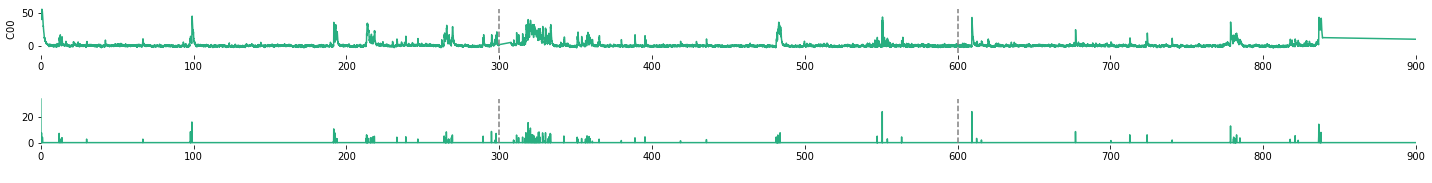

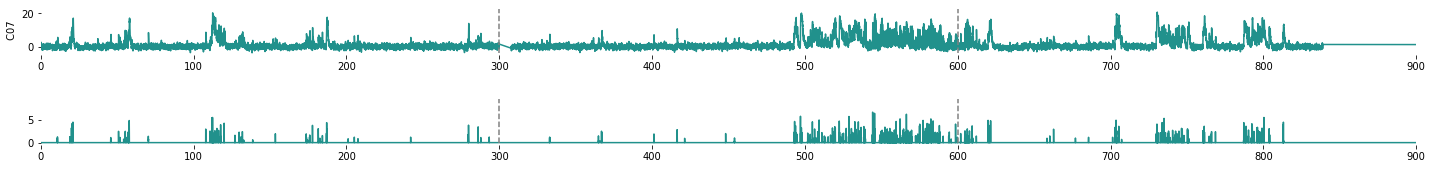

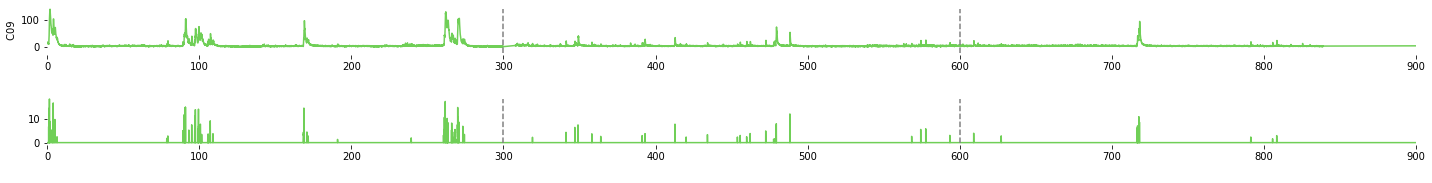

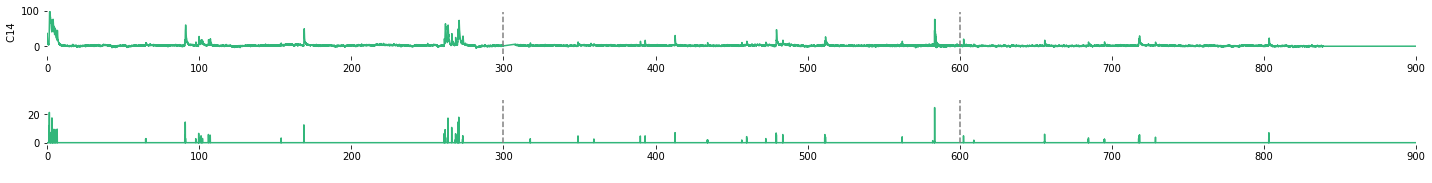

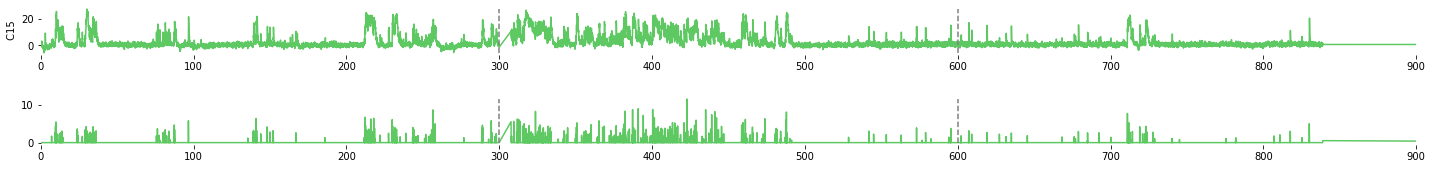

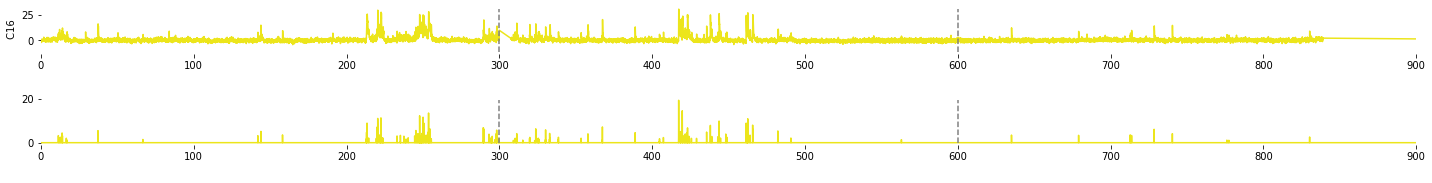

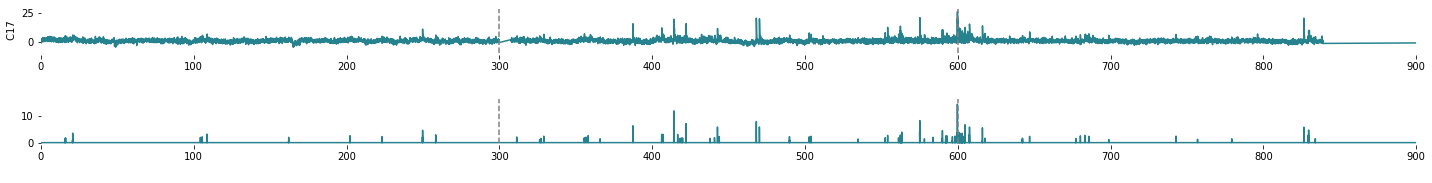

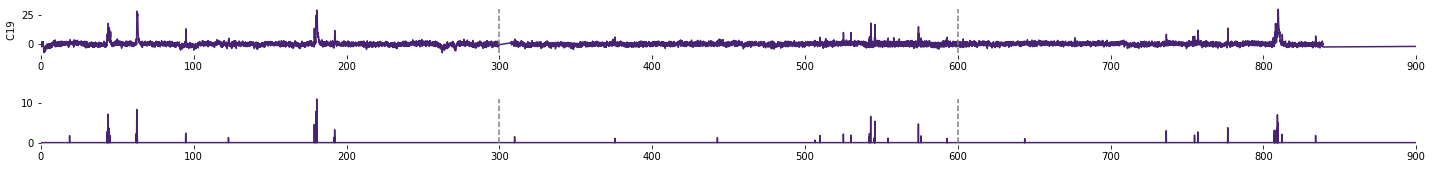

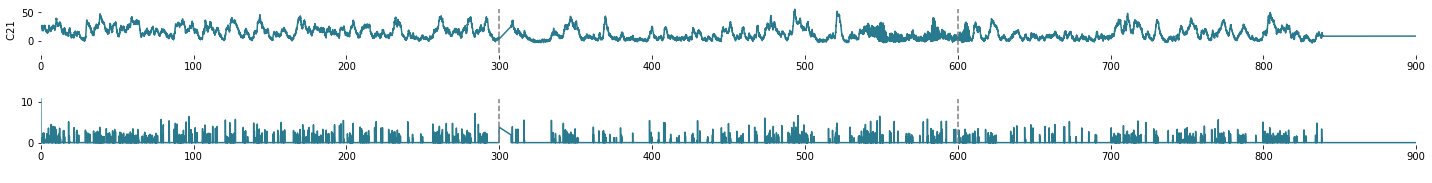

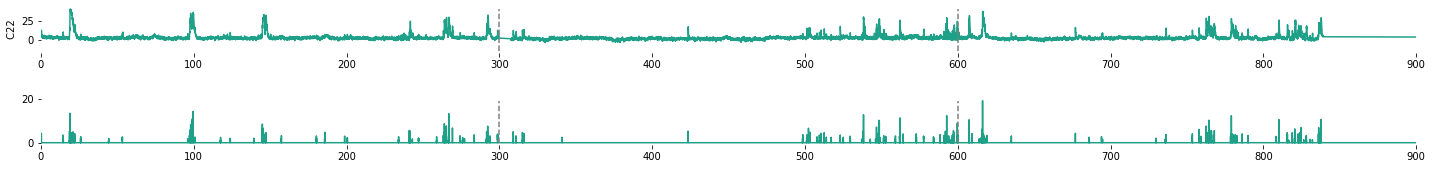

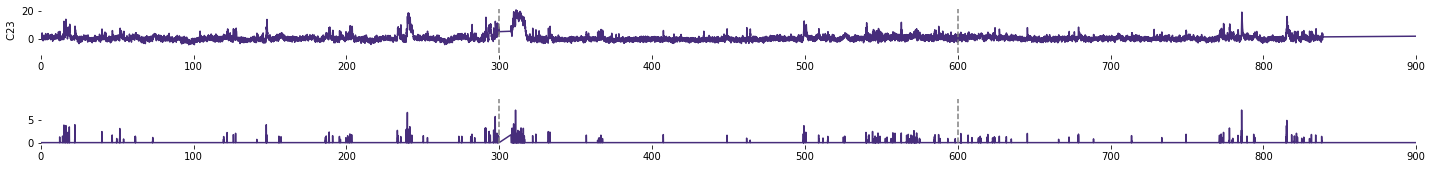

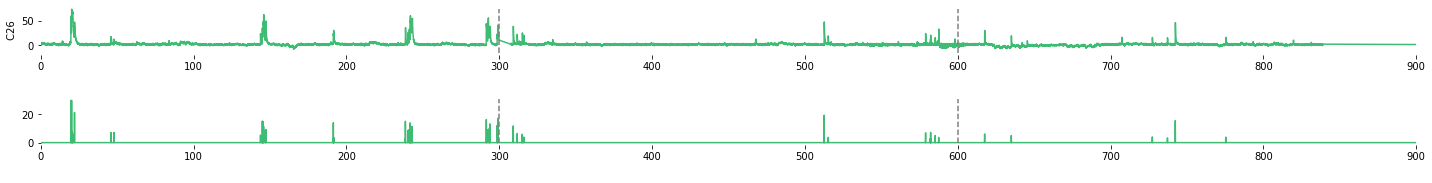

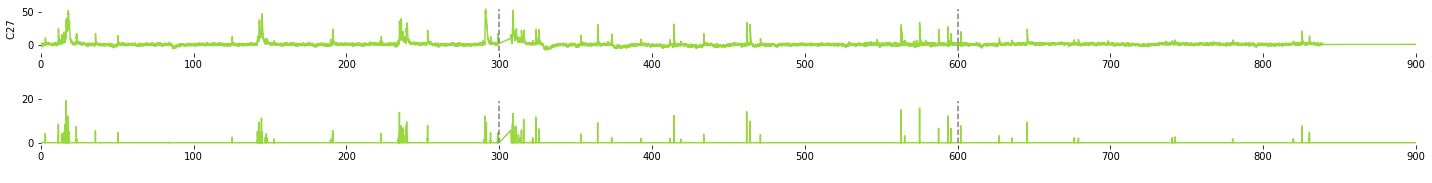

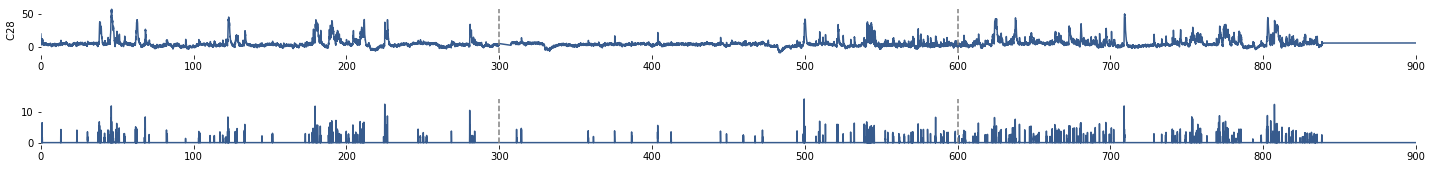

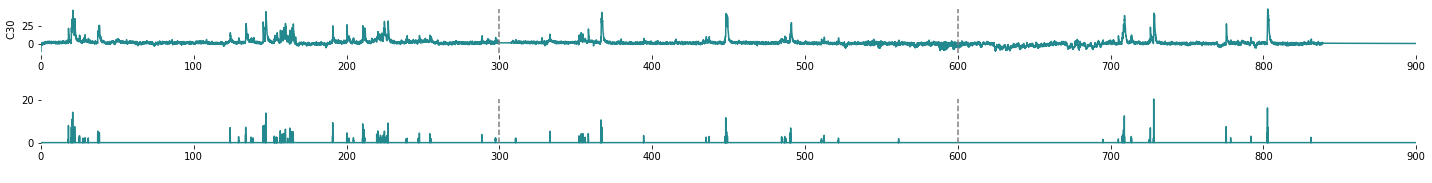

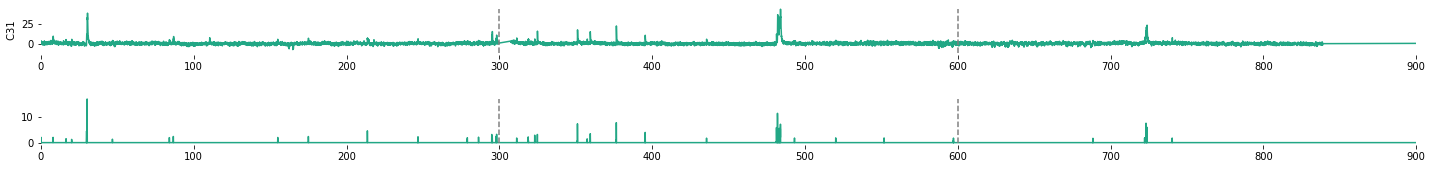

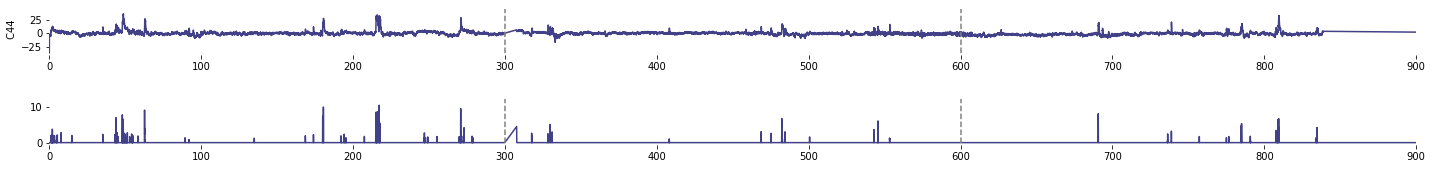

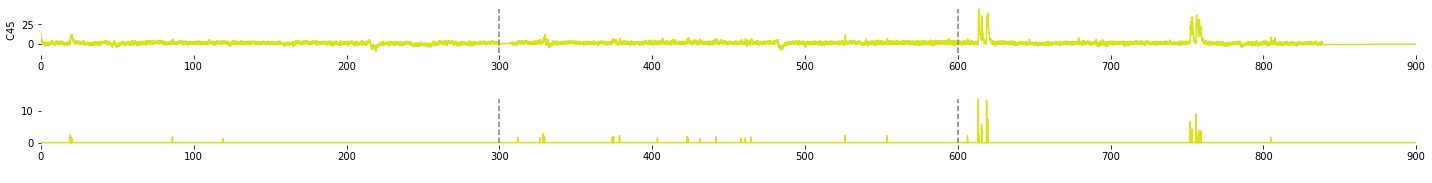

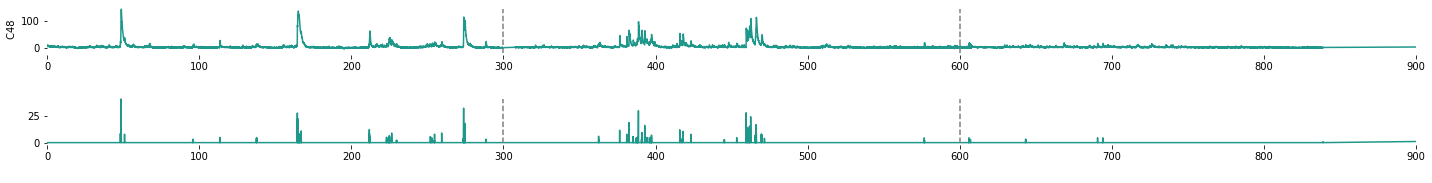

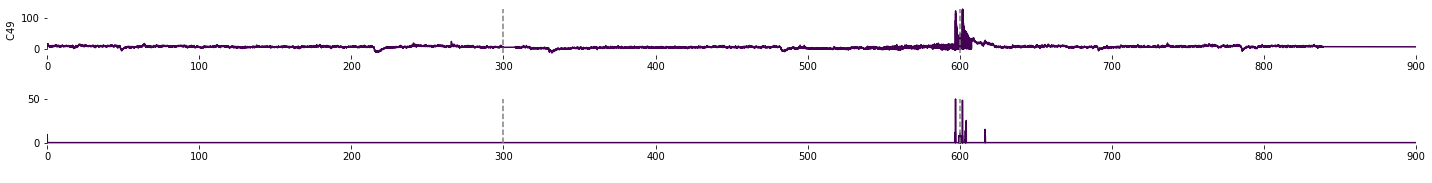

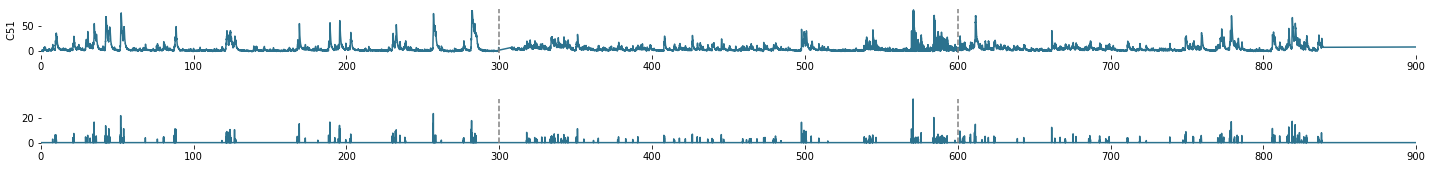

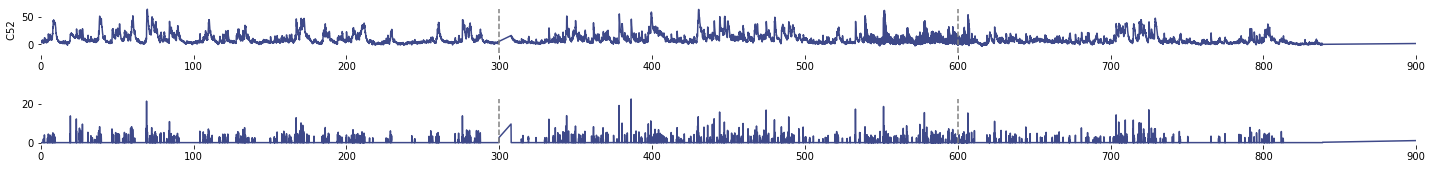

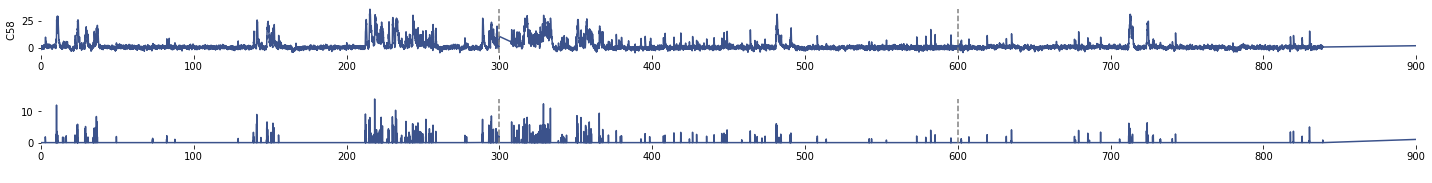

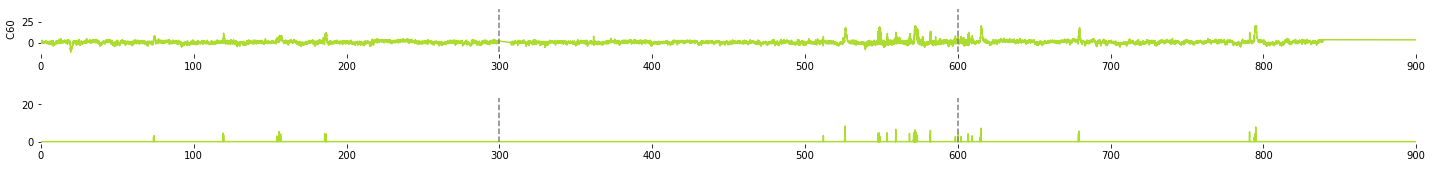

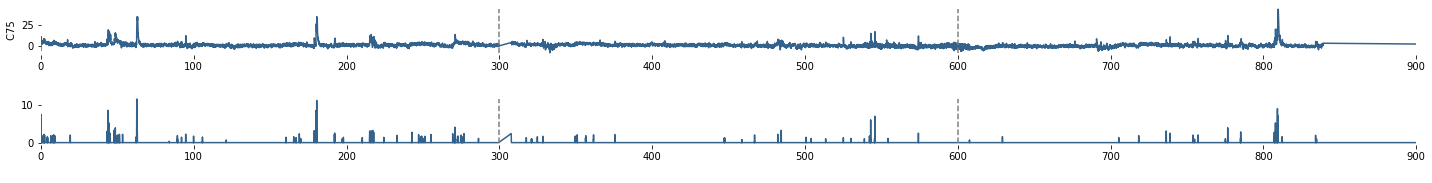

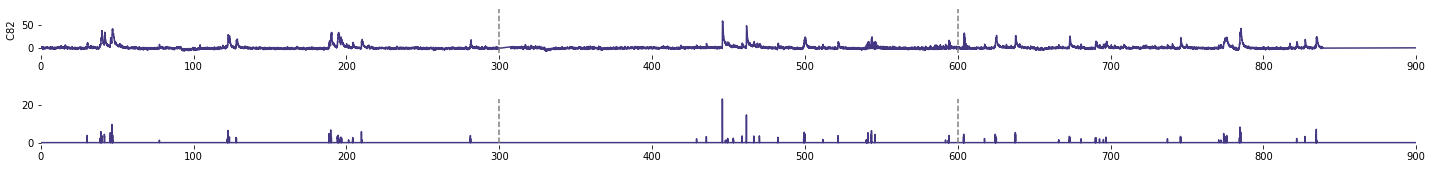

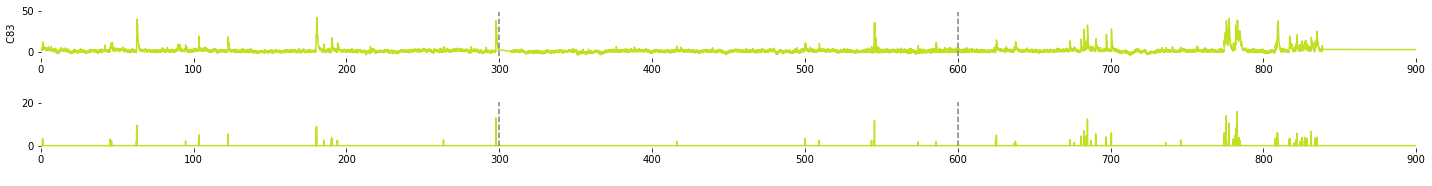

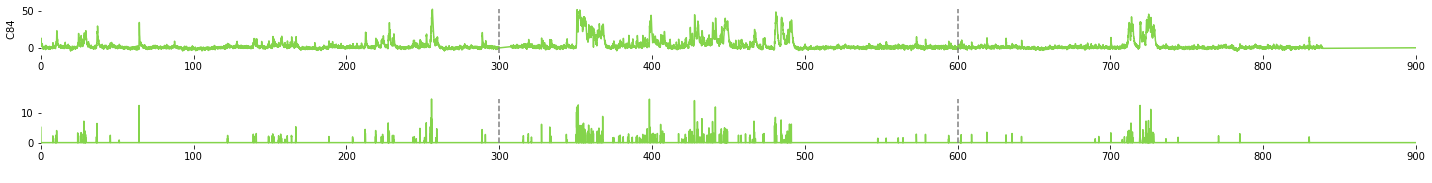

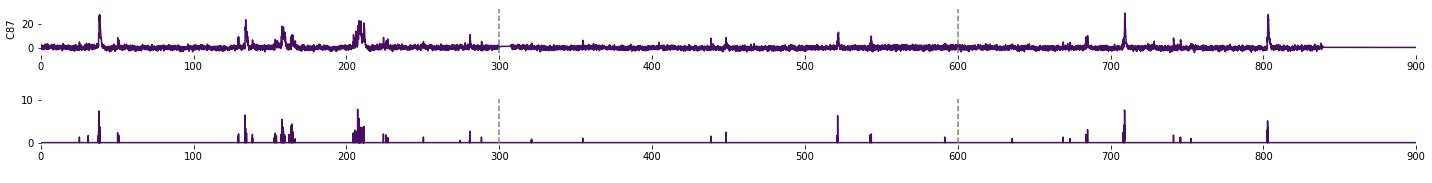

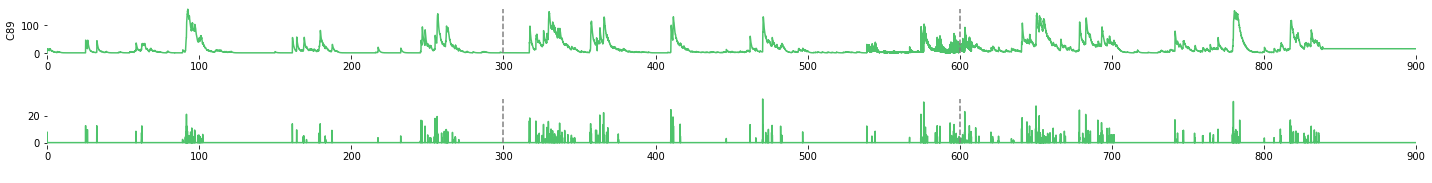

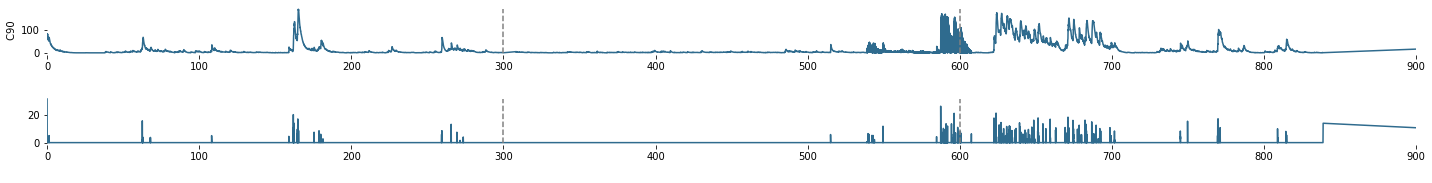

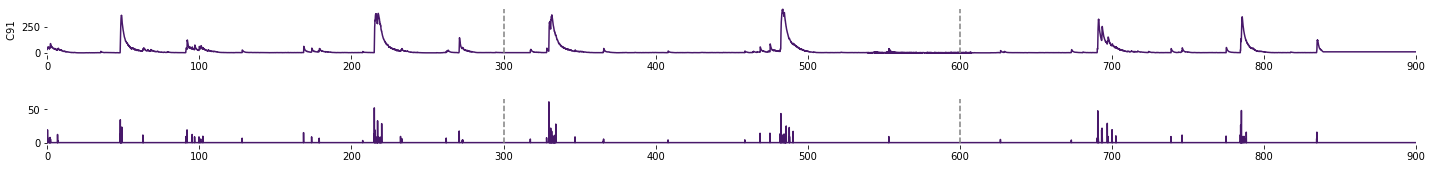

In [33]:
plot_data(output_folder="output_regular")

<ipython-input-32-d105a3b4f3ed>:28: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`).
  fig, ax = plt.subplots(1, 1)


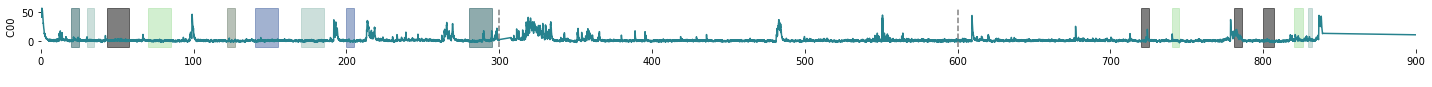

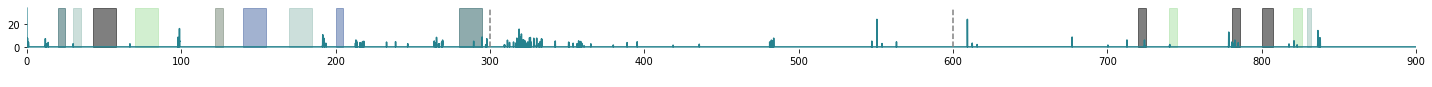

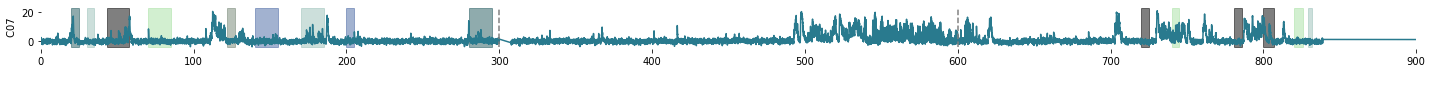

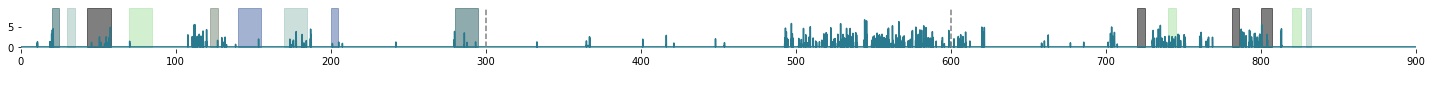

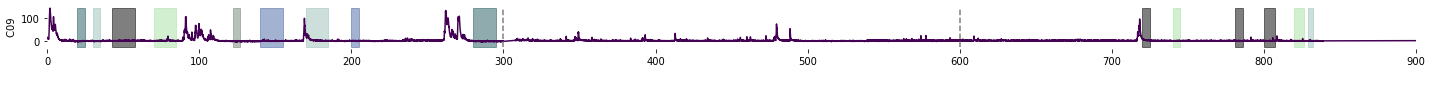

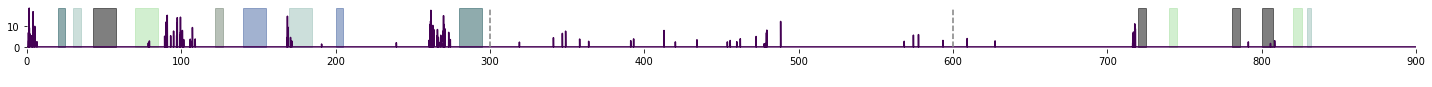

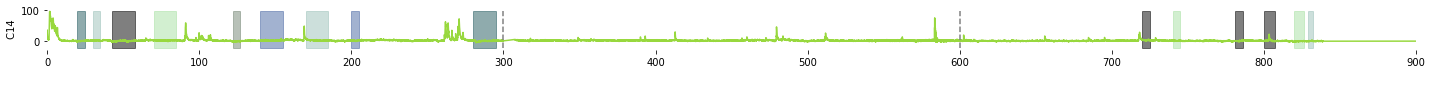

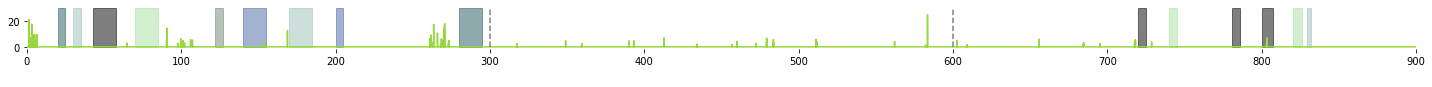

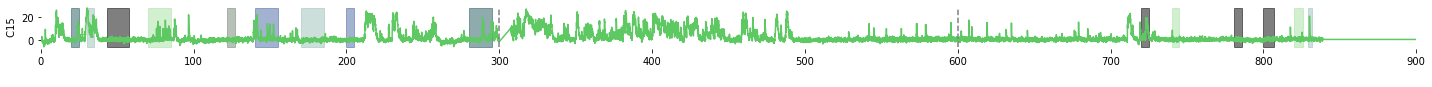

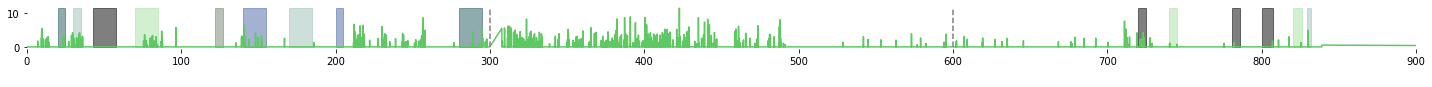

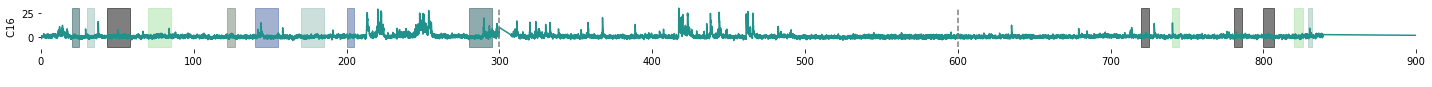

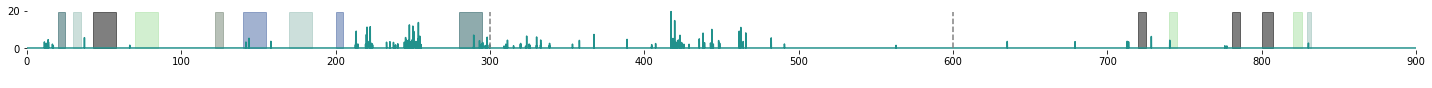

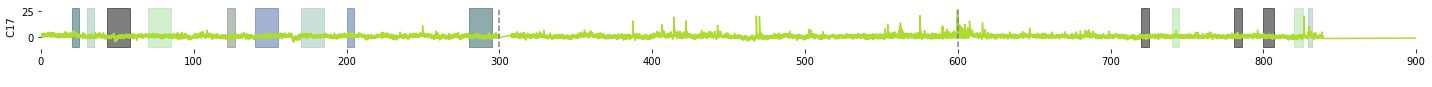

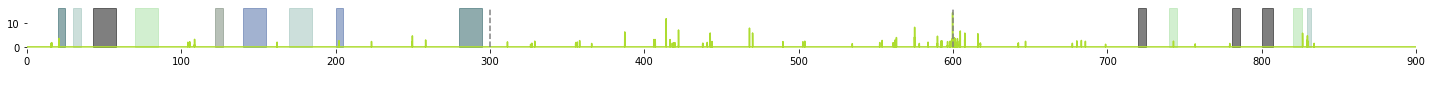

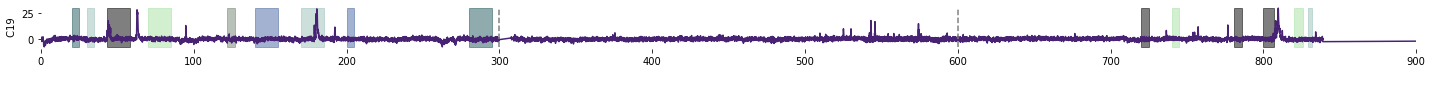

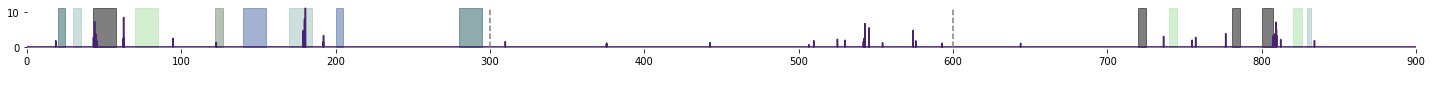

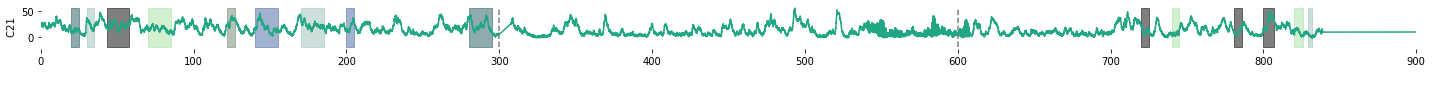

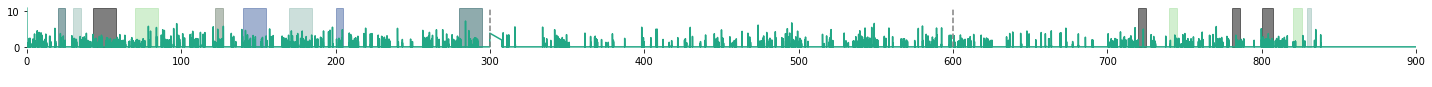

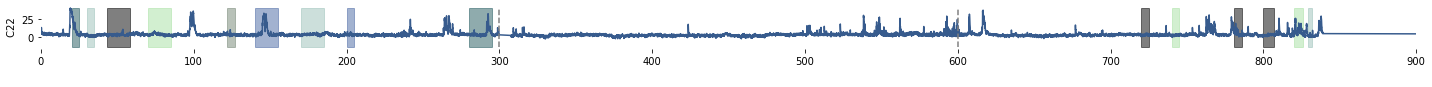

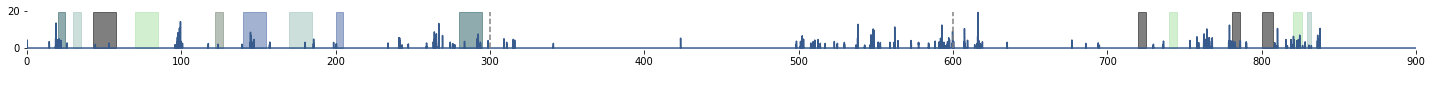

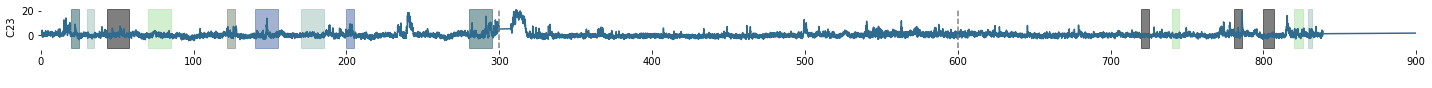

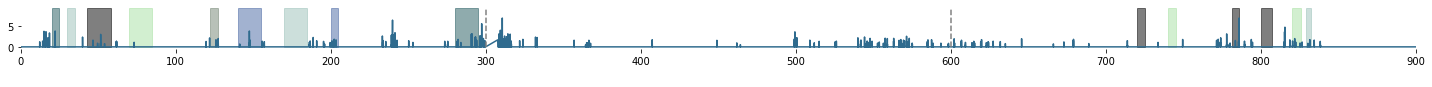

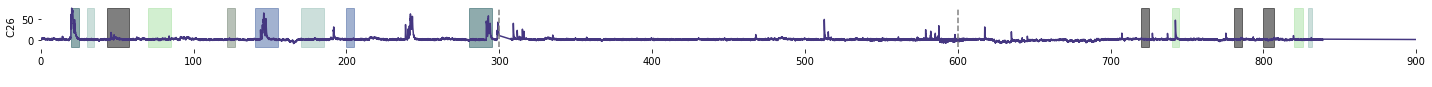

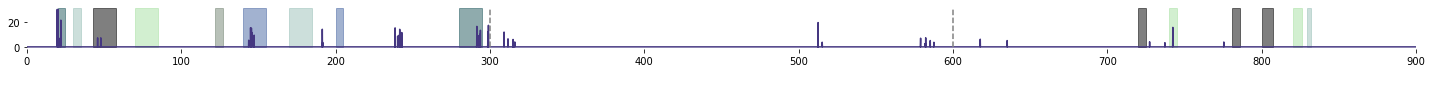

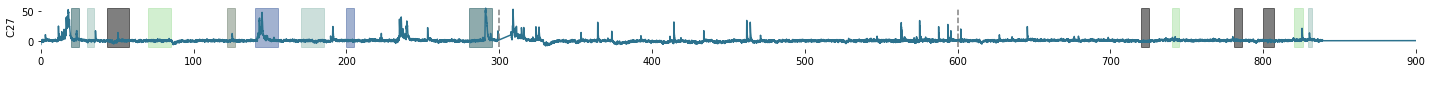

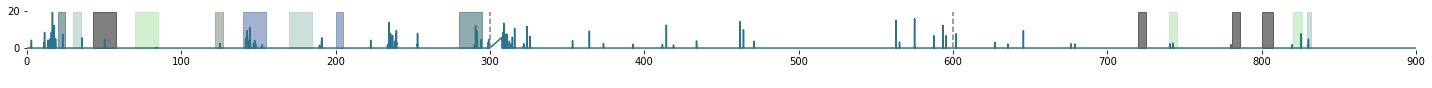

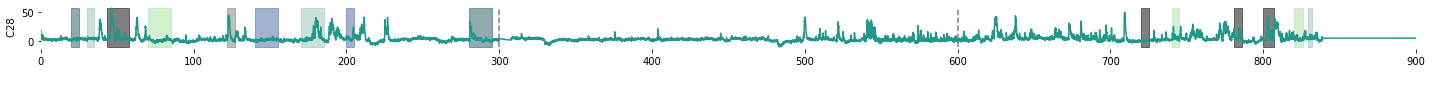

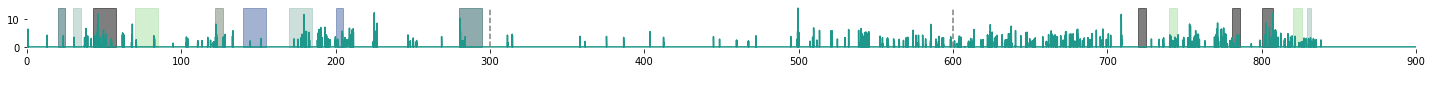

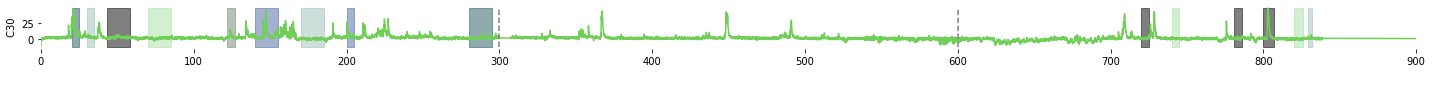

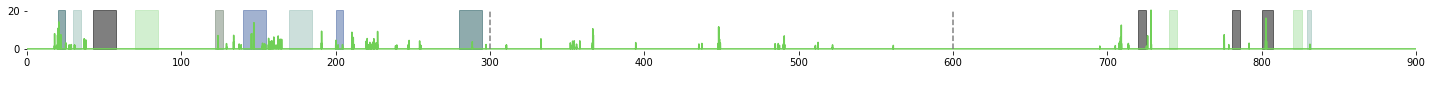

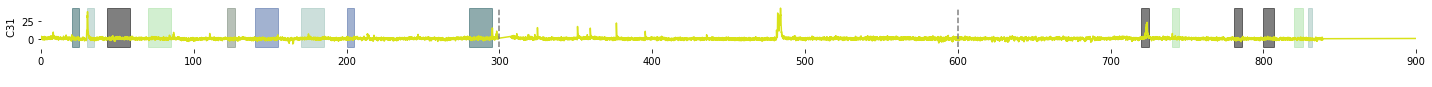

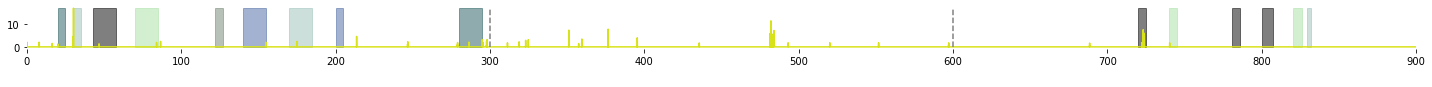

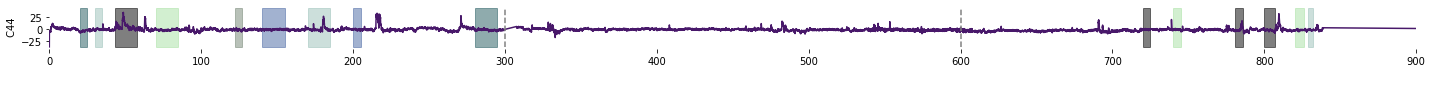

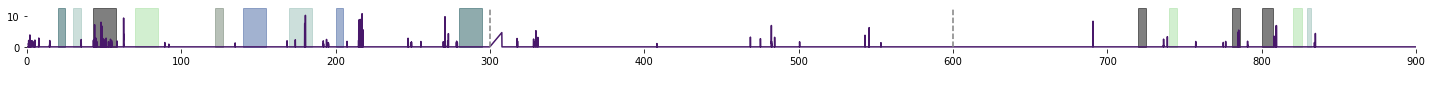

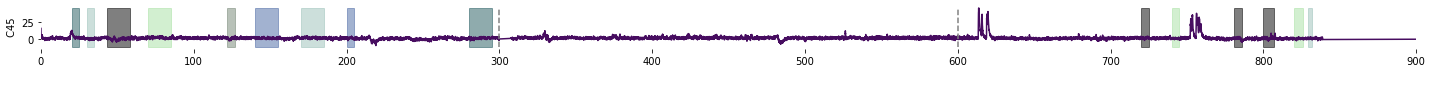

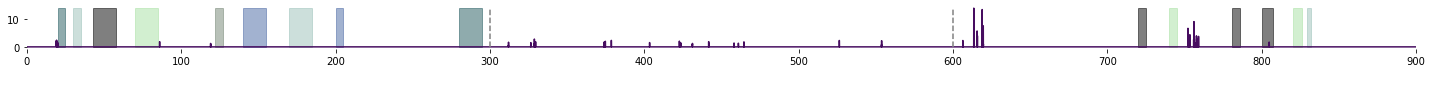

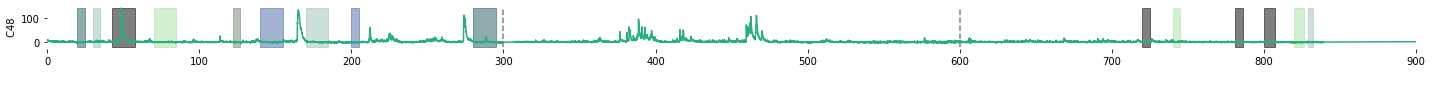

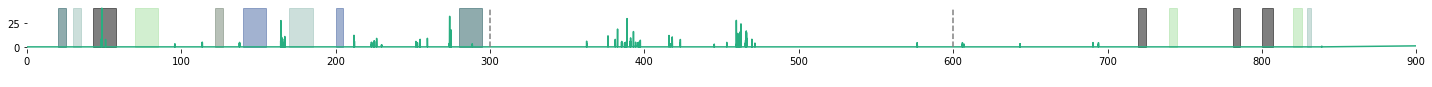

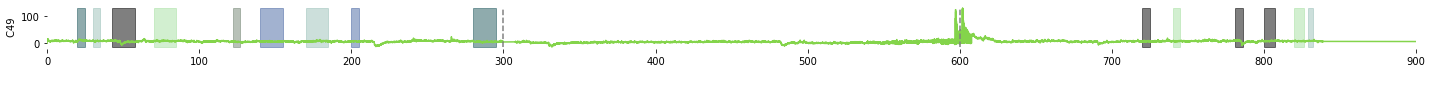

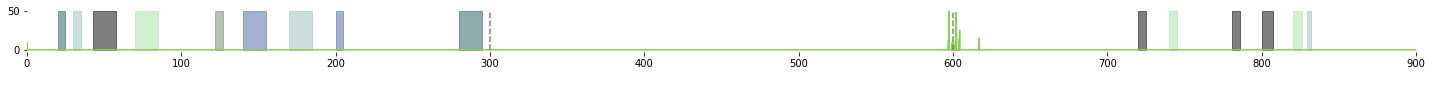

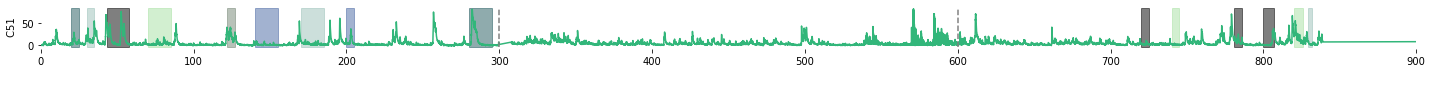

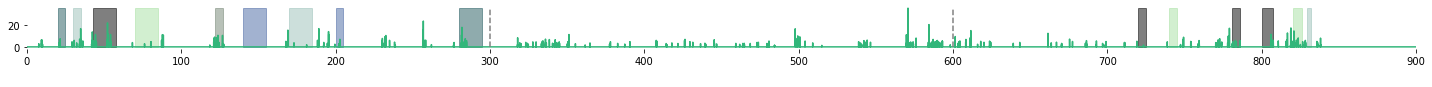

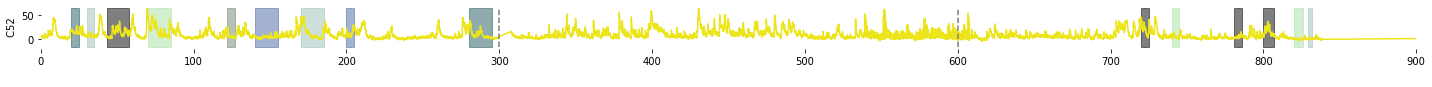

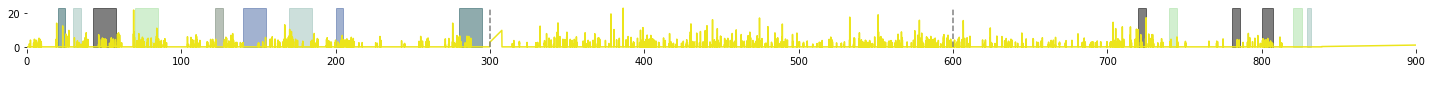

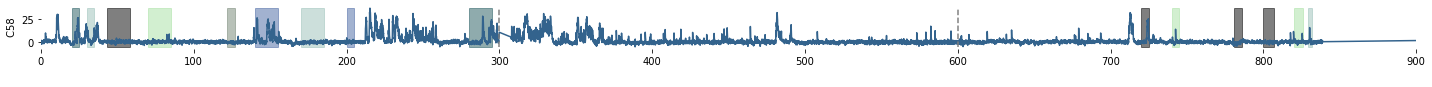

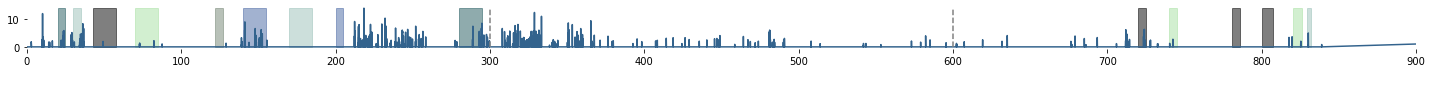

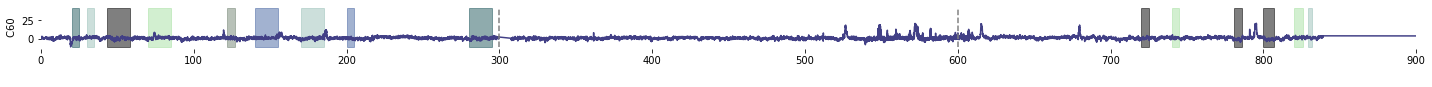

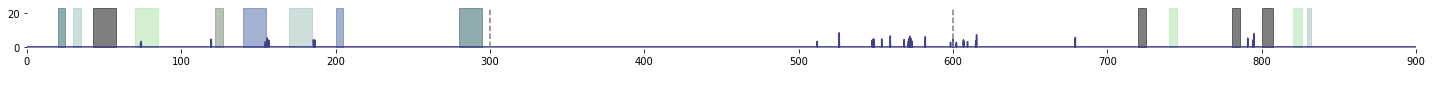

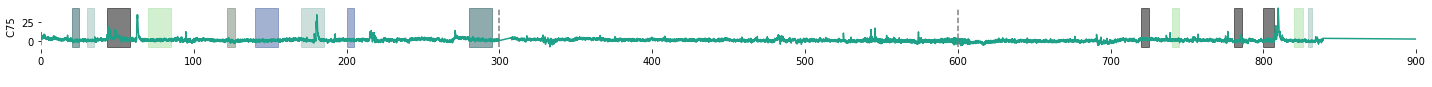

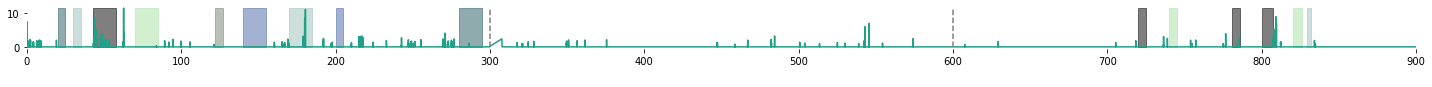

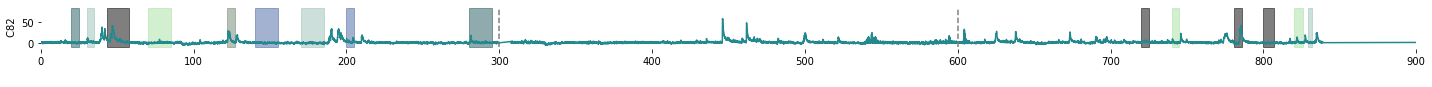

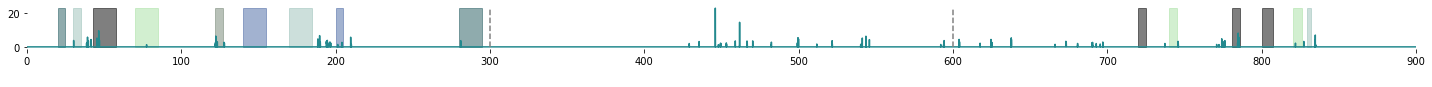

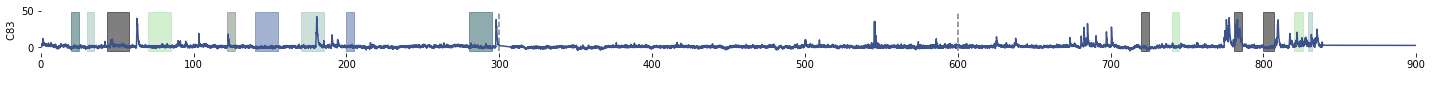

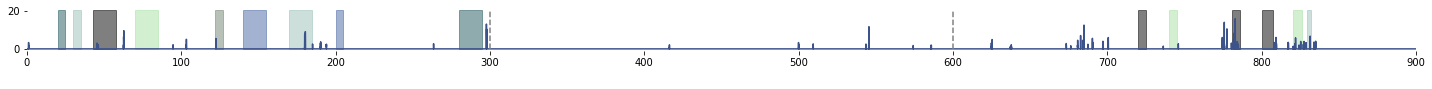

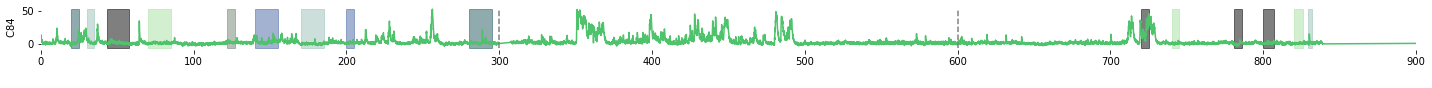

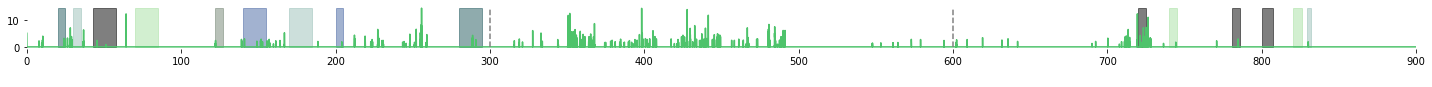

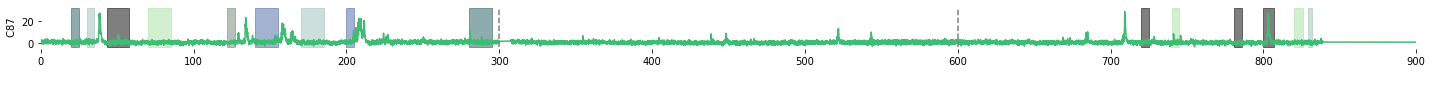

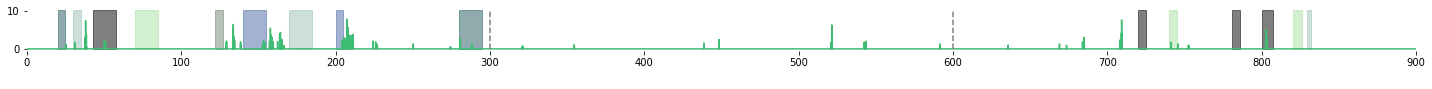

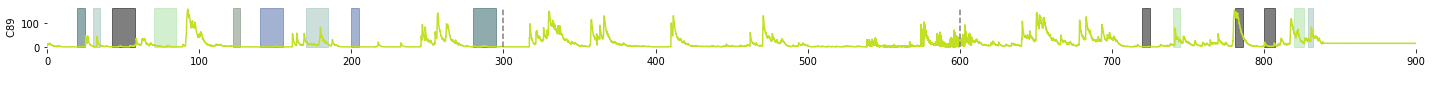

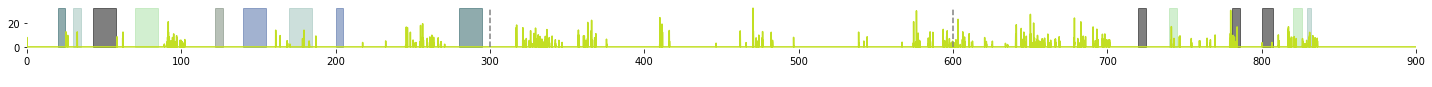

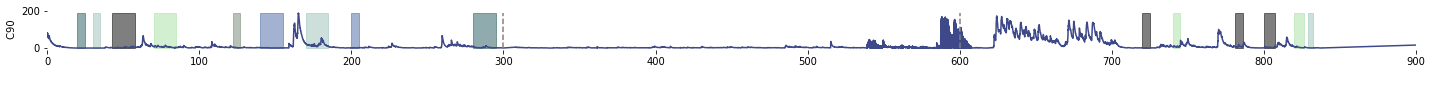

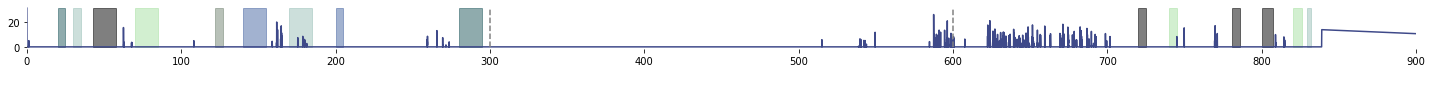

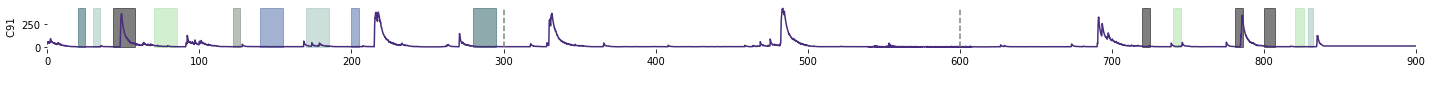

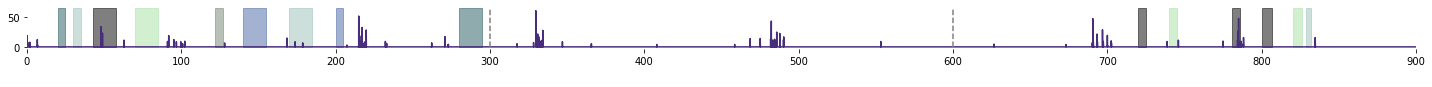

In [42]:
data_x_locations = [[20,5],[30,5],[43,15],[70,15],[122,5],[140,15],[170,15],[200,5],[280,15],
                    [720,5],[740,5],[781,5],[800,7],[820,6],[829,3]]
data_x_colors = [0,1,2,3,4,5,1,5,0,2,3,2,2,3,1]
data_x_palette = ["#21585d", "#9ac1b8", "#000000", "#a7e1a2", "#738472", "#4766a2"]
plot_data(output_folder="output_split_colored",
          data_x_locations=data_x_locations,
          data_x_colors=data_x_colors,
          data_x_palette=data_x_palette,
          colored_sections=True,
          split_figures=True)